# Monsoon convection plots

Functions in `plotter.jl` (docstrings there: `?plot_time_height`). Edits to `plotter.jl` take effect without restarting, through Revise. On the cluster, write PNGs instead:
`julia --project=plots -e 'include("plotter.jl"); save_plots("run/ekamsat-ctl0")'`

In [10]:
# plots/ is the folder with plotter.jl: look from where the kernel started, then at the usual checkouts (hpc, Mac)
candidates = (pwd(), joinpath(pwd(), "plots"), dirname(pwd()),
              "/ceoas/deszoeks/projects/monsoon-breeze/plots",
              expanduser("~/projects/monsoon-breeze/plots"))
plotsdir = candidates |> filter(d -> isfile(joinpath(d, "plotter.jl"))) |> first
cd(plotsdir)
using Pkg; Pkg.activate(plotsdir)
using Revise
includet(joinpath(plotsdir, "plotter.jl"))

rundir = joinpath(dirname(plotsdir), "run", "ekamsat-p3-ctl0")

  Activating project at `/ceoas/deszoeks/projects/monsoon-breeze/plots`


"/ceoas/deszoeks/projects/monsoon-breeze/run/ekamsat-p3-ctl0"

In [ ]:
anom(x) = x .- mean(x, dims=1)

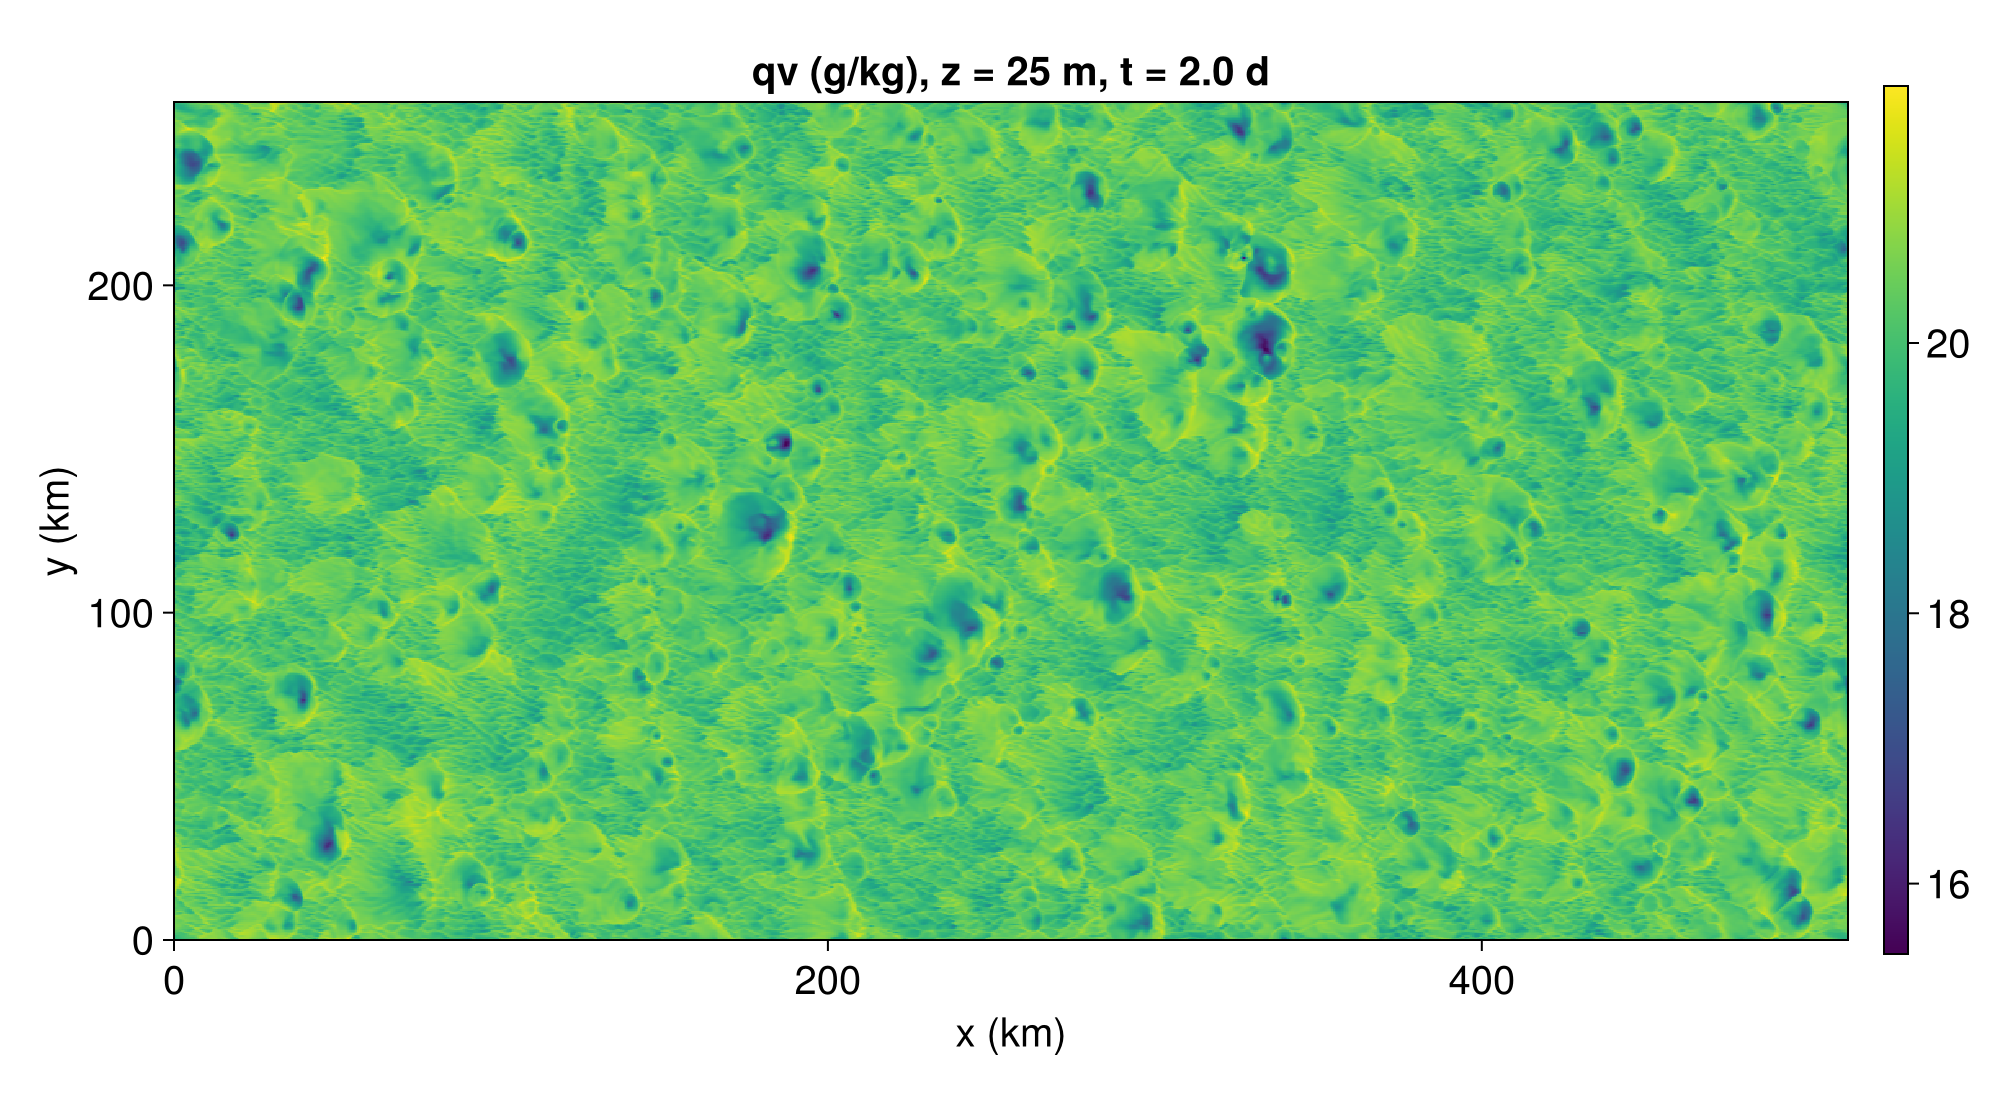

In [11]:
plot_xy(rundir, "qv"; n = last)            # lowest level, hourly (_surface.nc)

In [12]:
snapshot_times(rundir)                     # days of the 3D snapshots (_fields.nc)

3-element Vector{Float64}:
 0.0
 1.0
 2.0

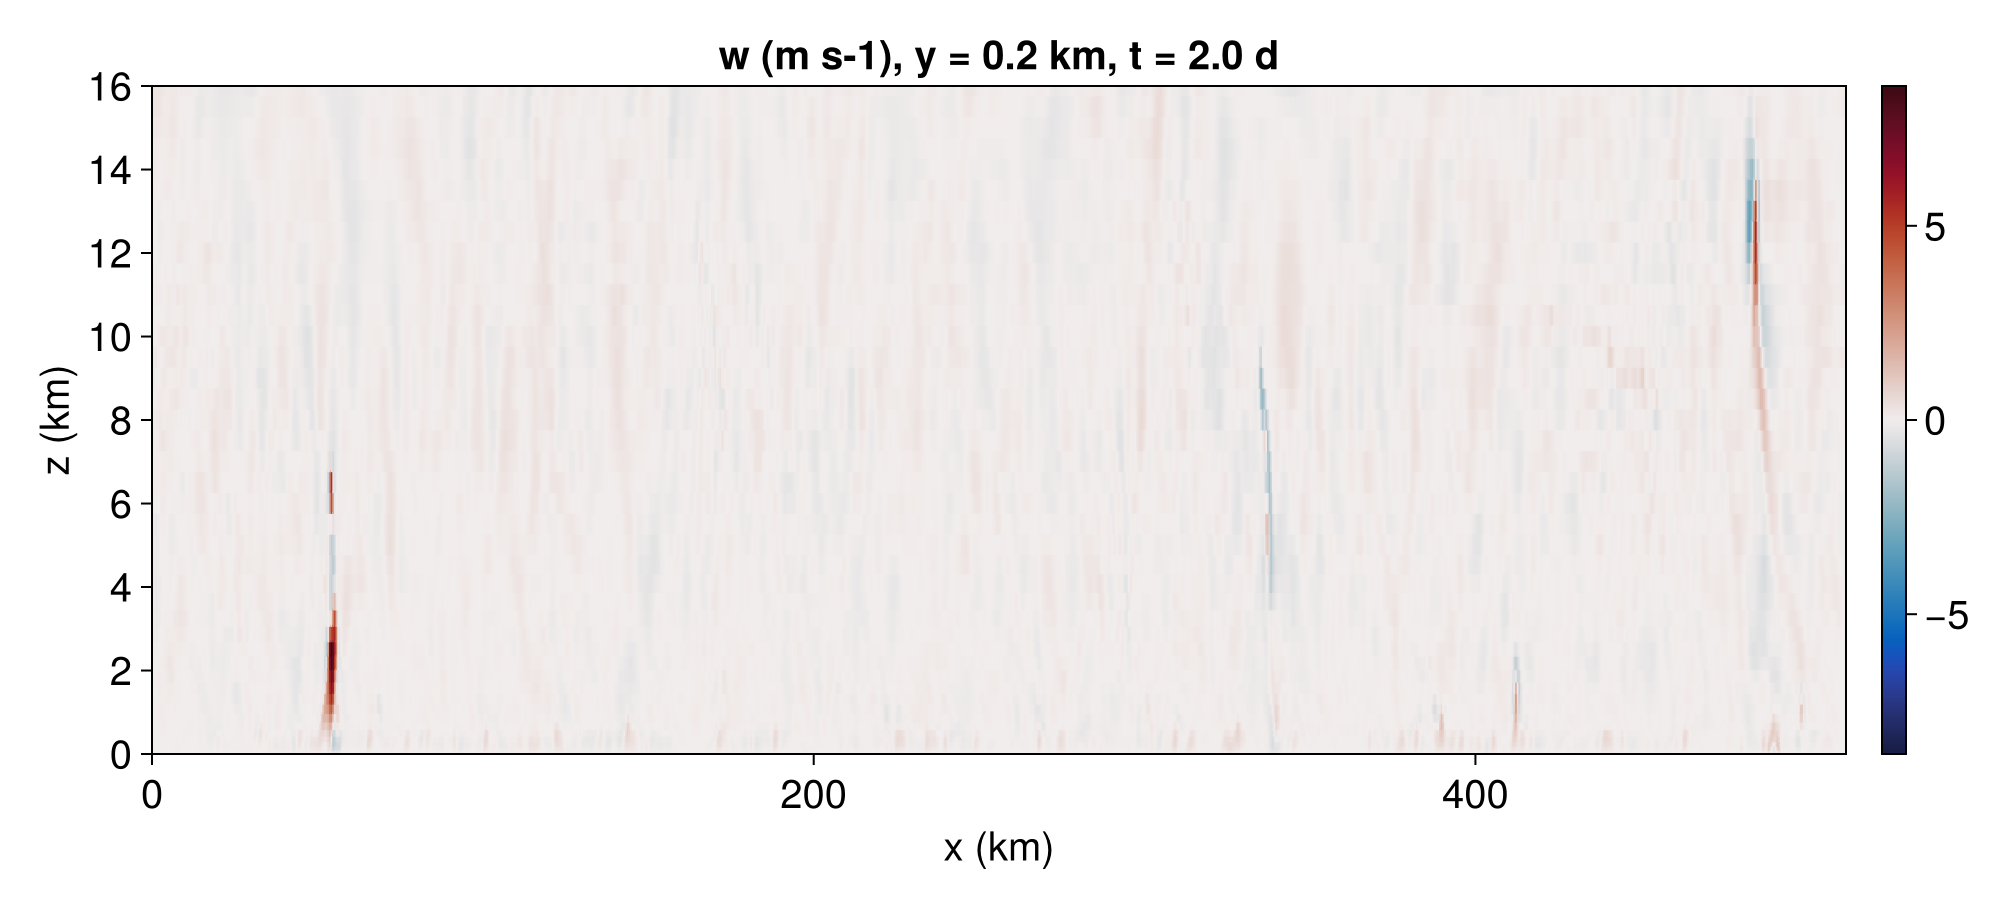

In [13]:
fig_xz = plot_xz(rundir, "w"; j = 1, n = last)

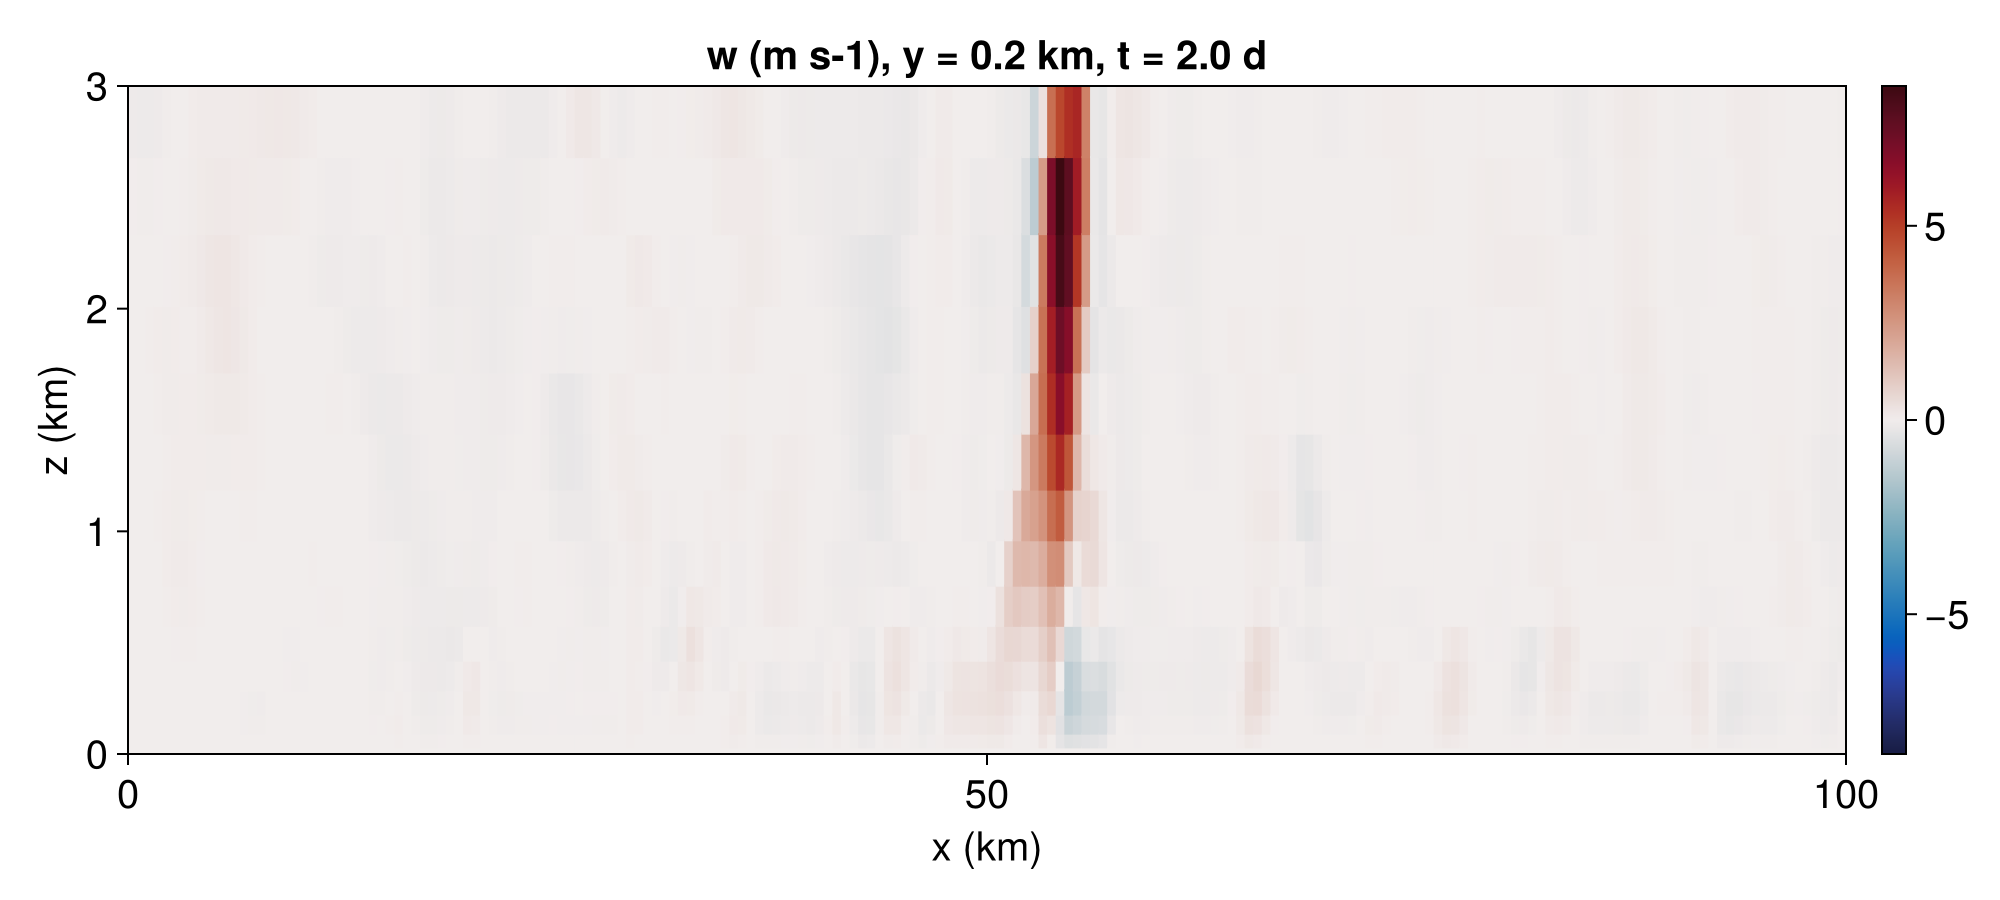

In [14]:
# Zoom the x–z section to the lowest 3 km and the first 100 km
ax = plot_axes(fig_xz)[1]
limits!(ax, 0, 100, 0, 3)     # x (km), z (km)
fig_xz

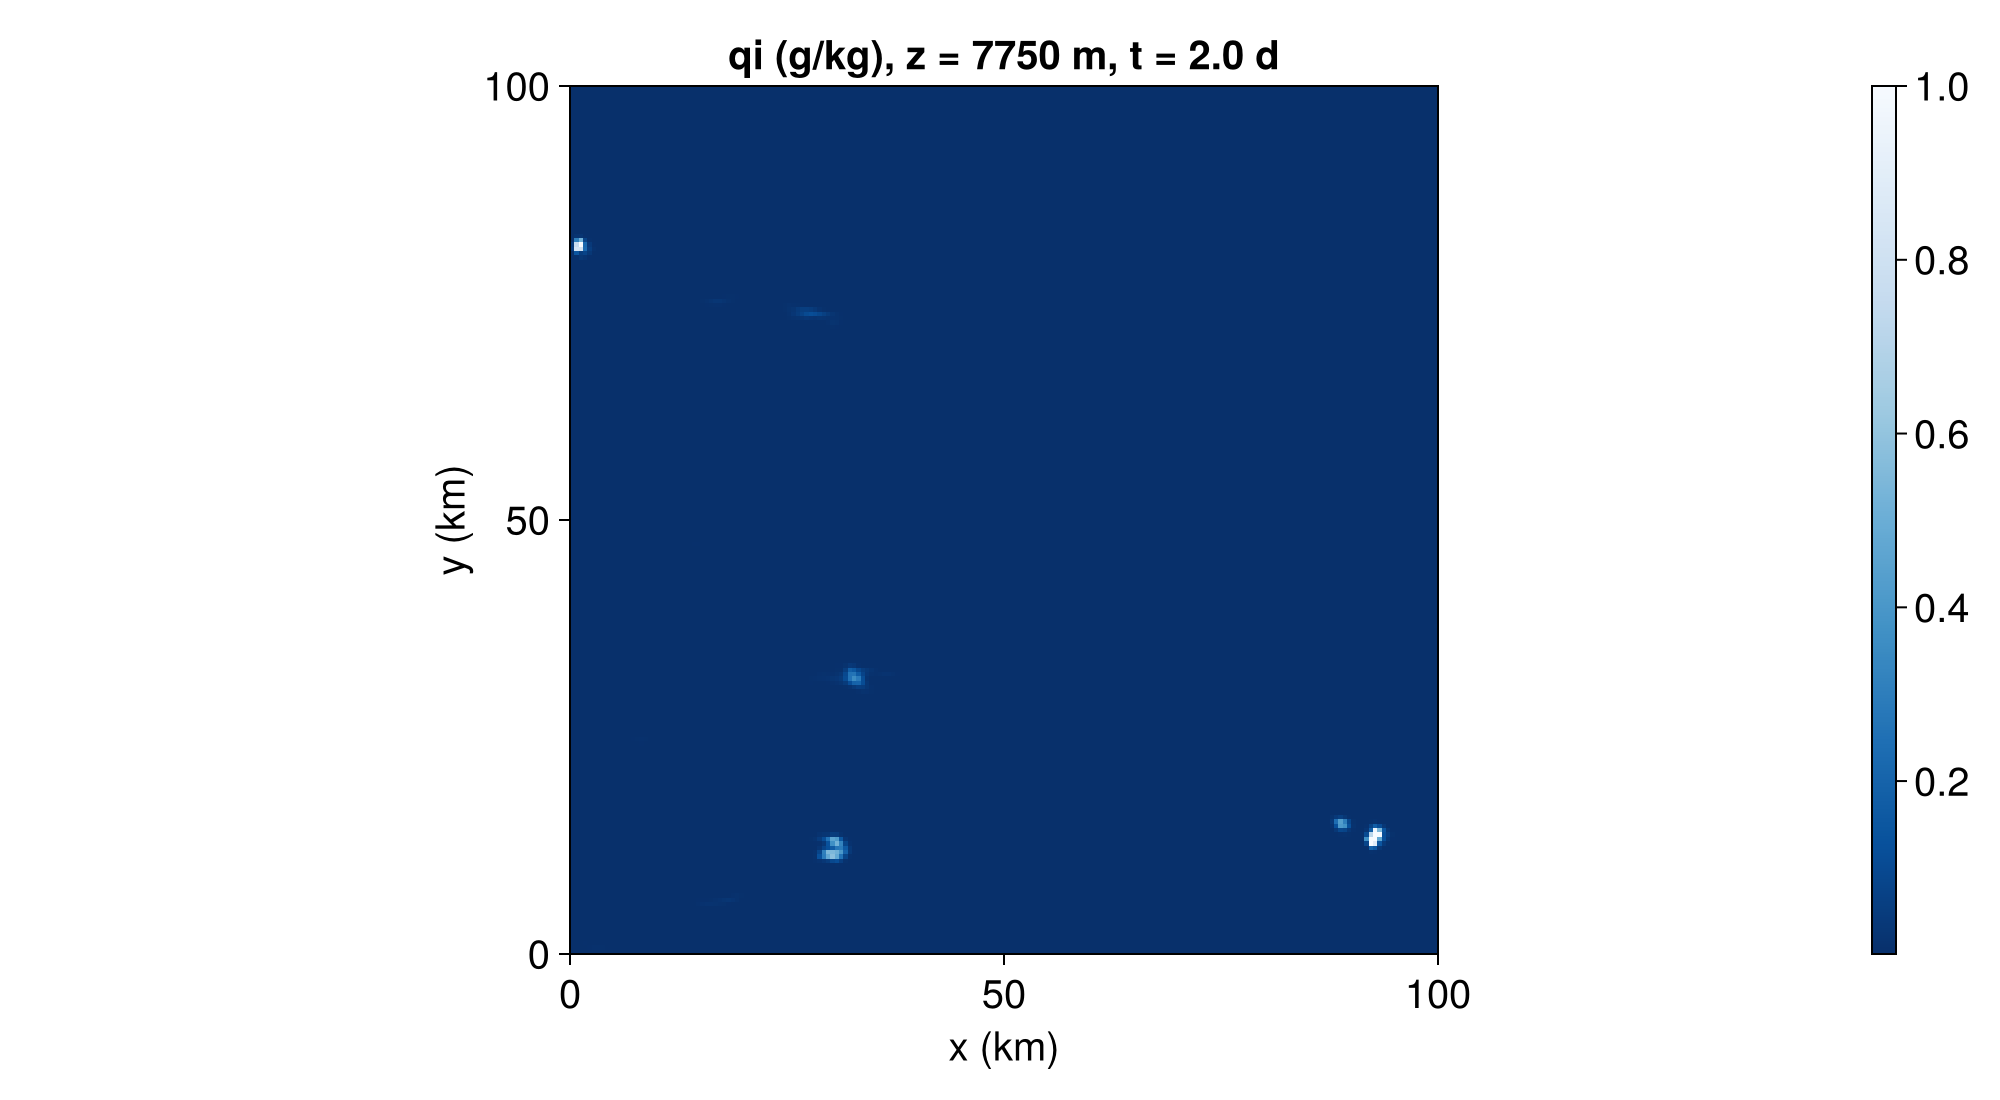

In [27]:
# log_10(x) = log10(max(x,1e-5))
fig_qcl = plot_xy(read_snapshot(rundir, "qcl"; n = last); z = 4_000)   # a level of a 3D snapshot
fig_qi  = plot_xy(read_snapshot(rundir, "qi" ; n = last); z = 8_000)   # a level of a 3D snapshot
fig_qf  = plot_xy(read_snapshot(rundir, "qf" ; n = last); z = 12_000)   # a level of a 3D snapshot

let fig = fig_qi
    ax = plot_axes(fig)[1]
    limits!(ax, 0, 100, 0, 100)
    hm = ax.scene.plots[1]     # the heatmap in the first axis
    hm.colorrange = (1e-3, 1)    # in the plotted units (log 10 g/kg here)
    hm.colormap = Reverse(:Blues)
    # hm.colorscale = log10
    fig
end

snapshot variables:
```
float Δx_caa(x_caa) ;
float Δx_faa(x_faa) ;
float Δy_aca(y_aca) ;
float Δy_afa(y_afa) ;
float Δz_aac(z_aac) ;
float Δz_aaf(z_aaf) ;
float T(time, z_aac, y_aca, x_caa) ;
float bf(time, z_aac, y_aca, x_caa) ;
float ni(time, z_aac, y_aca, x_caa) ;
float nr(time, z_aac, y_aca, x_caa) ;
float qcl(time, z_aac, y_aca, x_caa) ;
float qf(time, z_aac, y_aca, x_caa) ;
float qi(time, z_aac, y_aca, x_caa) ;
float qr(time, z_aac, y_aca, x_caa) ;
float qv(time, z_aac, y_aca, x_caa) ;
float qwi(time, z_aac, y_aca, x_caa) ;
float surface_temperature(time, y_aca, x_caa) ;
float theta(time, z_aac, y_aca, x_caa) ;
float u(time, z_aac, y_aca, x_faa) ;
float v(time, z_aac, y_afa, x_caa) ;
float w(time, z_aaf, y_aca, x_caa) ;
```

In [16]:
# The latest state, from the newest checkpoint
ck = read_checkpoint(rundir)
keys(ck.fields)

(:ρu, :ρv, :ρw, :ρθ, :ρqᵛ, :ρqᶜˡ, :ρqʳ, :ρnʳ, :ρqⁱ, :ρnⁱ, :ρqᶠ, :ρbᶠ, :ρqʷⁱ, :ρe)

In Breeze.jl (built on Oceananigans.jl framework dynamics), these fields represent density-weighted prognostic and diagnostic variables (\(\rho \times \psi\)) used by the compressible or anelastic solver.
The symbols combine the atmospheric fluid dynamics variables with the Predicted Particle Properties (P3) microphysics scheme:

```
🌀 Momentum & Energetics

• :ρu — Z-momentum density (\(\rho u\)); air density multiplied by zonal velocity (\(x\)-direction).
• :ρv — Meridional momentum density (\(\rho v\)); air density multiplied by meridional velocity (\(y\)-direction).
• :ρw — Vertical momentum density (\(\rho w\)); air density multiplied by vertical velocity (\(z\)-direction).
• :ρθ — Potential temperature density (\(\rho \theta\)); total energy-state variable tracking heat.
• :ρe — Total energy density (or turbulent kinetic energy density \(\rho e\)), depending on your chosen closure.

💨 Vapor & Liquid Phase Fields

• :ρqᵛ — Water vapor mass density (\(\rho q_v\)); mass of water vapor per unit volume.
• :ρqᶜˡ — Cloud liquid water mass density (\(\rho q_{cl}\)); mass of suspended liquid cloud droplets per unit volume.
• :ρqʳ — Rain water mass density (\(\rho q_r\)); mass of precipitating liquid water.
• :ρnʳ — Rain number concentration density (\(\rho N_r\)); total number of raindrops per unit volume.

❄️ P3 Property-Based Ice Phase Fields

The P3 scheme dynamically evolves ice properties rather than separating them into distinct categories like graupel or snow:
• :ρqⁱ — Total ice mass density (\(\rho q_i\)); total mass concentration of all ice deposition/crystal particles.
• :ρnⁱ — Total ice number concentration density (\(\rho N_i\)); total number of ice crystals per unit volume.
• :ρqᶠ — Rimed ice mass density (\(\rho q_f\) or \(Q_{rim}\)); mass concentration of liquid water rimed onto ice crystals.
• :ρbᶠ — Rime volume density (\(\rho b_f\) or \(B_{rim}\)); tracks rime volume to dynamically compute ice particle density.
• :ρqʷⁱ — Liquid water fraction mass density on ice (\(\rho q_{wi}\)); tracks liquid water mass residing on or inside melting ice particles (for wet snow/hail transition).
```

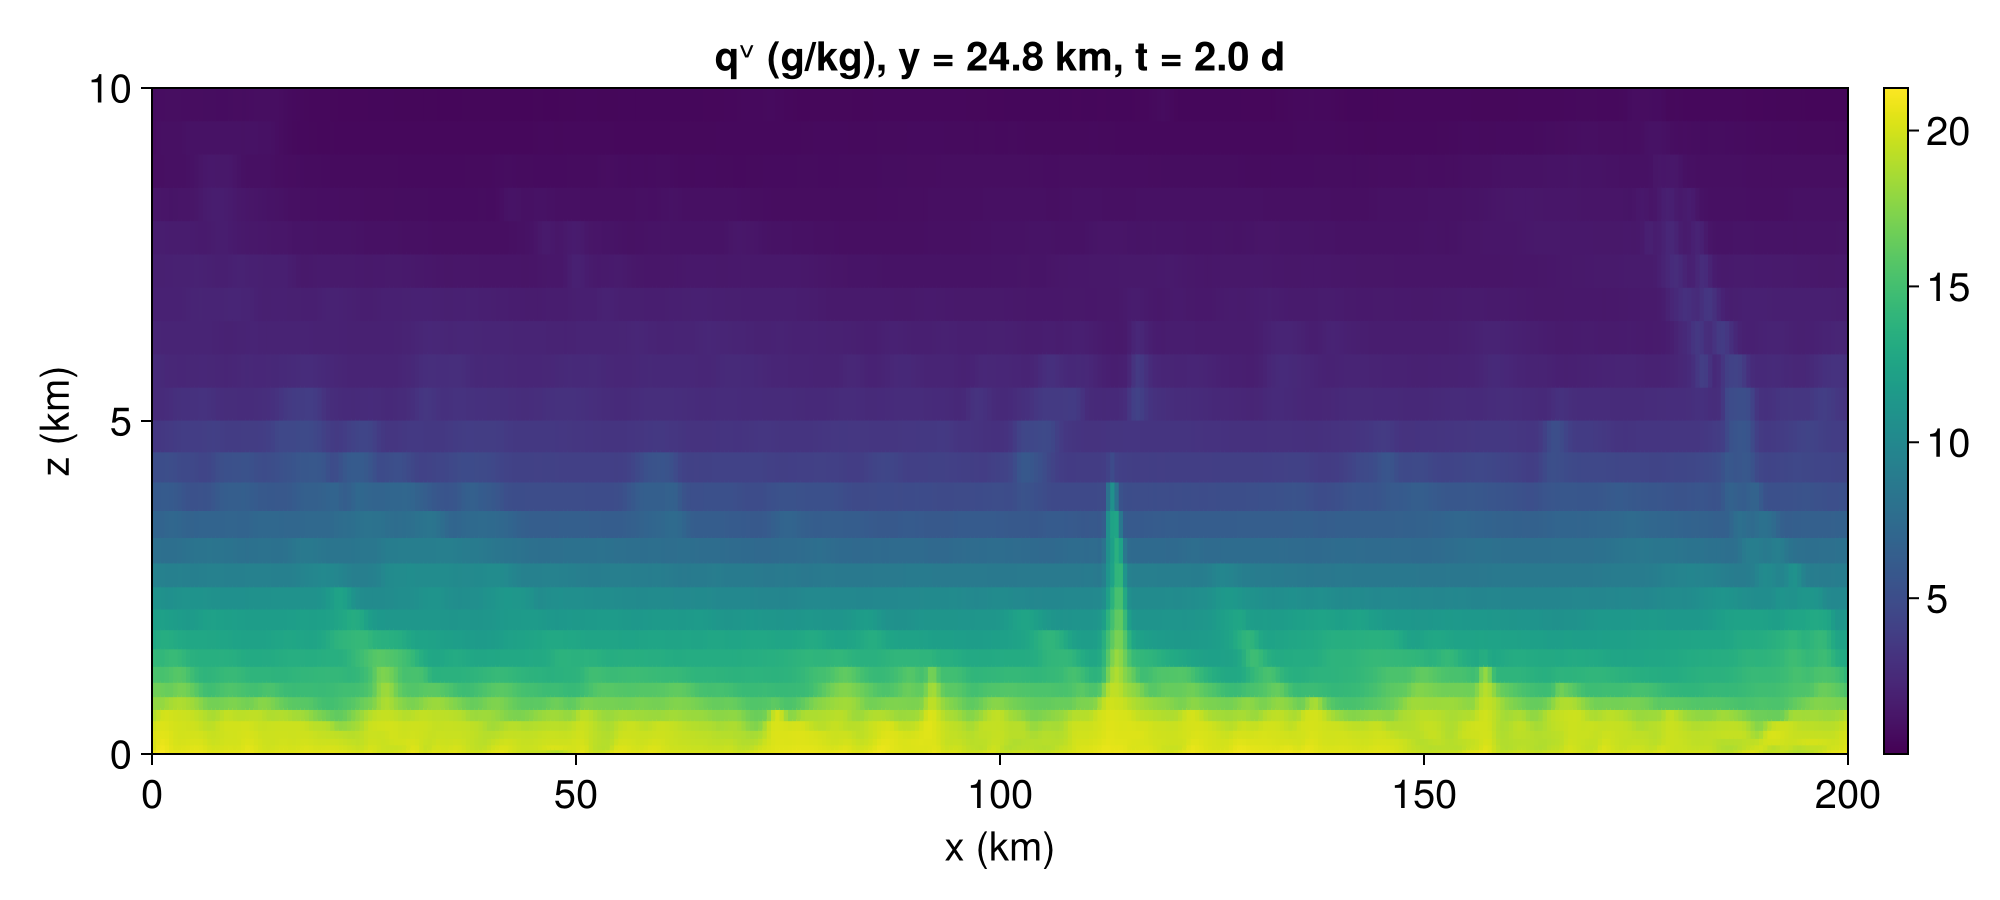

In [38]:
let fig = plot_xz(anom, checkpoint_snapshot(ck, :ρqᵛ); j = 50)
    ax = plot_axes(fig)[1]
    limits!(ax, 0, 200, 0, 10)
    fig
end

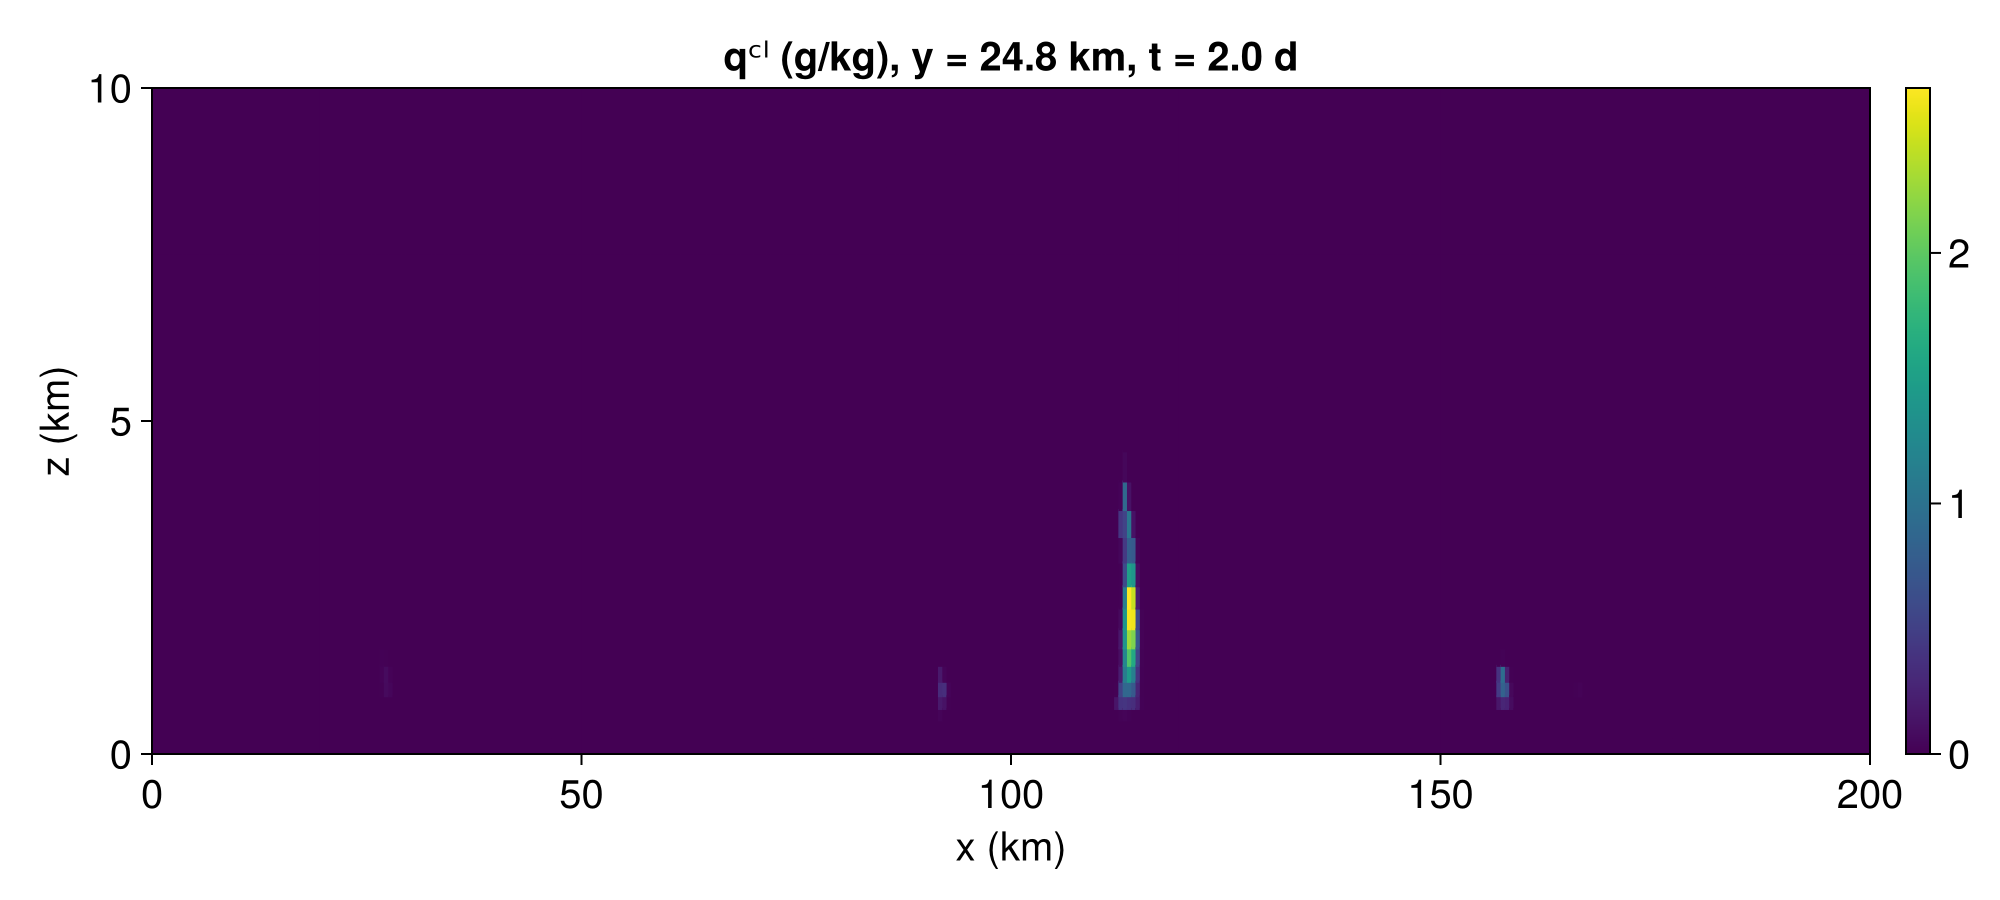

In [40]:
let fig = plot_xz(checkpoint_snapshot(ck, :ρqᶜˡ); j = 50)
    ax = plot_axes(fig)[1]
    limits!(ax, 0, 200, 0, 10)
    fig
end
